In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Load processed dataset

df = pd.read_csv(
    "../data/processed/telco_churn_cleaned.csv"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()


Dataset loaded successfully!
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:

# Calculate churn distribution

churn_counts = df["Churn"].value_counts()

print("Customer Churn Distribution:")
print(churn_counts)

# Calculate percentages
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print("\nChurn Percentage:")
print(churn_percentage.round(2))


Customer Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


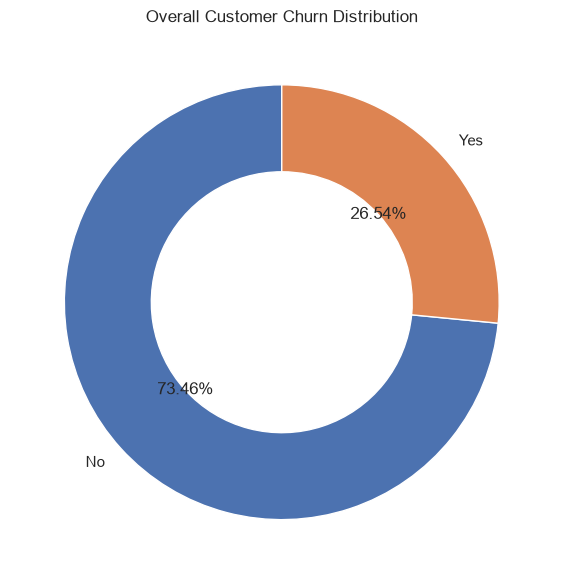

In [38]:

# Overall Customer Churn Distribution

plt.figure(figsize=(8, 6))

plt.pie(
    churn_counts,
    labels=churn_counts.index,
    autopct="%1.2f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Overall Customer Churn Distribution")

plt.tight_layout()

# Save visualization
plt.savefig(
    "../visuals/01_overall_churn_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [5]:

# Churn analysis by Contract Type

contract_churn = (
    df.groupby("Contract")["Churn"]
    .value_counts(normalize=True)
    .unstack(fill_value=0) * 100
)

print(contract_churn.round(2))


Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


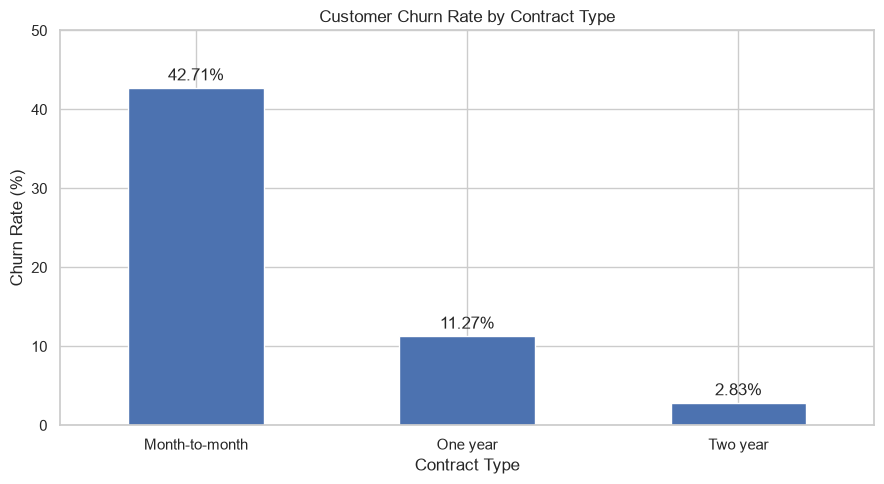

In [7]:

# Improved contract churn visualization

ax = contract_churn["Yes"].sort_values(
    ascending=False
).plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.ylim(0, 50)
plt.tight_layout()
plt.show()


In [8]:

# Create tenure groups

def tenure_group(tenure):

    if tenure <= 12:
        return "New (0-12 months)"

    elif tenure <= 24:
        return "Early (13-24 months)"

    elif tenure <= 48:
        return "Mid-term (25-48 months)"

    else:
        return "Long-term (49-72 months)"


df["TenureGroup"] = df["tenure"].apply(tenure_group)

df[["tenure", "TenureGroup"]].head(10)


,tenure,TenureGroup
0,1,New (0-12 months)
1,34,Mid-term (25-48 months)
2,2,New (0-12 months)
3,45,Mid-term (25-48 months)
4,2,New (0-12 months)
5,8,New (0-12 months)
6,22,Early (13-24 months)
7,10,New (0-12 months)
8,28,Mid-term (25-48 months)
9,62,Long-term (49-72 months)


In [9]:

# Calculate churn rate by tenure group

tenure_churn = (
    df.groupby("TenureGroup")["Churn"]
    .value_counts(normalize=True)
    .unstack(fill_value=0) * 100
)

tenure_churn = tenure_churn.reindex([
    "New (0-12 months)",
    "Early (13-24 months)",
    "Mid-term (25-48 months)",
    "Long-term (49-72 months)"
])

print(tenure_churn.round(2))


Churn                        No    Yes
TenureGroup                           
New (0-12 months)         52.56  47.44
Early (13-24 months)      71.29  28.71
Mid-term (25-48 months)   79.61  20.39
Long-term (49-72 months)  90.49   9.51


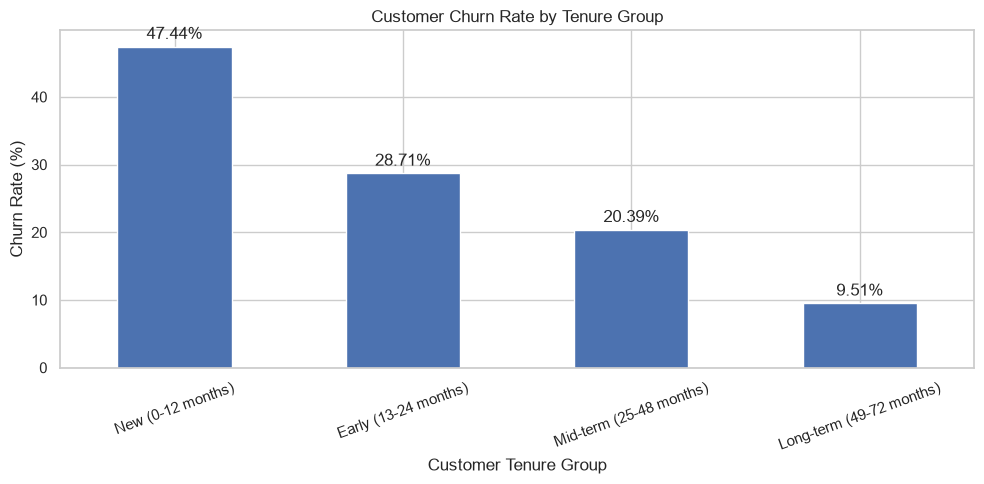

In [10]:

# Churn rate by tenure group

ax = tenure_churn["Yes"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Customer Churn Rate by Tenure Group")
plt.xlabel("Customer Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()


In [11]:

# Churn analysis by Payment Method

payment_churn = (
    df.groupby("PaymentMethod")["Churn"]
    .value_counts(normalize=True)
    .unstack(fill_value=0) * 100
)

print(payment_churn.round(2))


Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


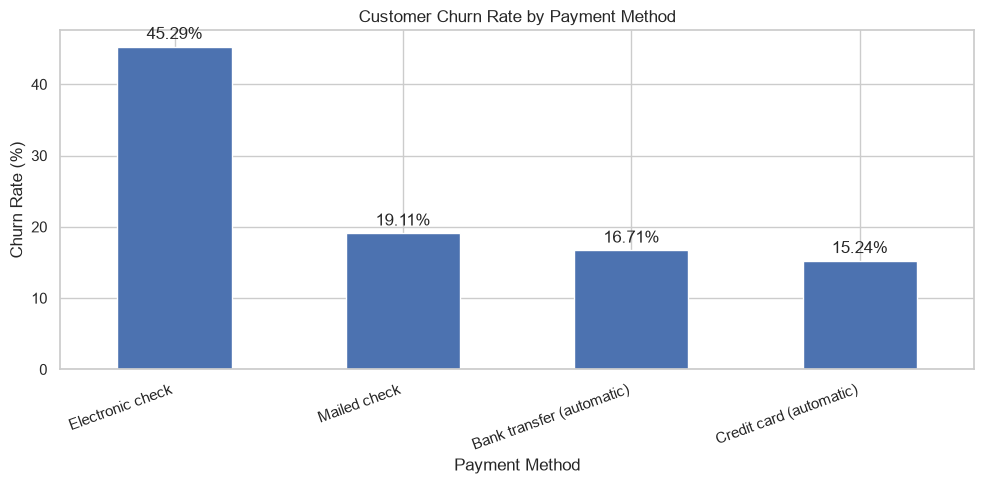

In [12]:

# Visualize churn rate by payment method

payment_churn_rate = payment_churn["Yes"].sort_values(
    ascending=False
)

ax = payment_churn_rate.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20, ha="right")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()


In [13]:

# Churn analysis by Internet Service

internet_churn = (
    df.groupby("InternetService")["Churn"]
    .value_counts(normalize=True)
    .unstack(fill_value=0) * 100
)

print(internet_churn.round(2))


Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


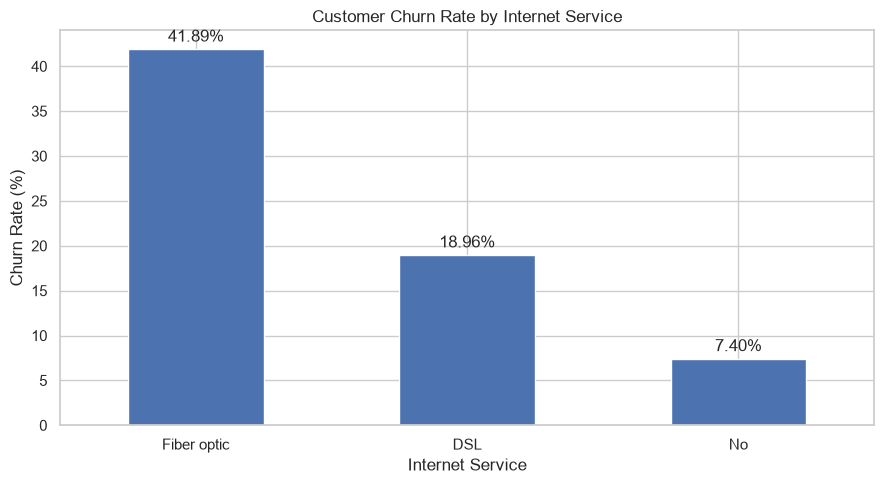

In [14]:

# Visualize churn rate by internet service

internet_churn_rate = internet_churn["Yes"].sort_values(
    ascending=False
)

ax = internet_churn_rate.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Customer Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()


In [15]:

# Function to calculate churn rate for individual services

def analyze_service_churn(df, service):

    result = (
        df.groupby(service)["Churn"]
        .value_counts(normalize=True)
        .unstack(fill_value=0) * 100
    )

    return result.round(2)


# Analyze Online Security
security_churn = analyze_service_churn(
    df, "OnlineSecurity"
)

print("Online Security Churn Analysis:")
print(security_churn)


Online Security Churn Analysis:
Churn                   No    Yes
OnlineSecurity                   
No                   58.23  41.77
No internet service  92.60   7.40
Yes                  85.39  14.61


In [16]:

# List of additional services

services = [
    "OnlineSecurity",
    "TechSupport",
    "OnlineBackup",
    "DeviceProtection",
    "StreamingTV",
    "StreamingMovies"
]

# Analyze each service
for service in services:

    print("\n", "=" * 50)
    print(f"Churn Analysis: {service}")
    print("=" * 50)

    result = analyze_service_churn(df, service)

    print(result)



Churn Analysis: OnlineSecurity
Churn                   No    Yes
OnlineSecurity                   
No                   58.23  41.77
No internet service  92.60   7.40
Yes                  85.39  14.61

Churn Analysis: TechSupport
Churn                   No    Yes
TechSupport                      
No                   58.36  41.64
No internet service  92.60   7.40
Yes                  84.83  15.17

Churn Analysis: OnlineBackup
Churn                   No    Yes
OnlineBackup                     
No                   60.07  39.93
No internet service  92.60   7.40
Yes                  78.47  21.53

Churn Analysis: DeviceProtection
Churn                   No    Yes
DeviceProtection                 
No                   60.87  39.13
No internet service  92.60   7.40
Yes                  77.50  22.50

Churn Analysis: StreamingTV
Churn                   No    Yes
StreamingTV                      
No                   66.48  33.52
No internet service  92.60   7.40
Yes                  69.93  30

In [17]:

# Consolidated churn analysis for all six services

service_summary = []

for service in services:

    result = analyze_service_churn(df, service)

    service_summary.append({
        "Service": service,
        "Without Service (%)": result.loc["No", "Yes"],
        "With Service (%)": result.loc["Yes", "Yes"],
        "No Internet Service (%)": result.loc[
            "No internet service", "Yes"
        ]
    })

service_summary_df = pd.DataFrame(service_summary)

service_summary_df = service_summary_df.set_index("Service")

print(service_summary_df.round(2))


                  Without Service (%)  With Service (%)  \
Service                                                   
OnlineSecurity                  41.77             14.61   
TechSupport                     41.64             15.17   
OnlineBackup                    39.93             21.53   
DeviceProtection                39.13             22.50   
StreamingTV                     33.52             30.07   
StreamingMovies                 33.68             29.94   

                  No Internet Service (%)  
Service                                    
OnlineSecurity                        7.4  
TechSupport                           7.4  
OnlineBackup                          7.4  
DeviceProtection                      7.4  
StreamingTV                           7.4  
StreamingMovies                       7.4  


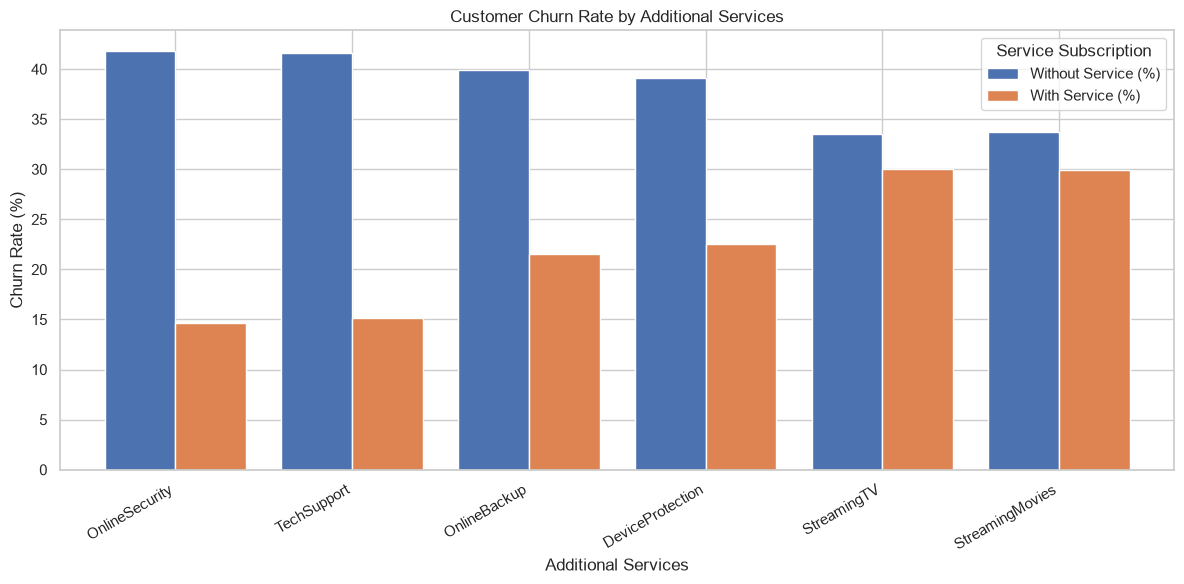

In [18]:

# Compare churn rates across additional services

ax = service_summary_df[
    ["Without Service (%)", "With Service (%)"]
].plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Customer Churn Rate by Additional Services")
plt.xlabel("Additional Services")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30, ha="right")

plt.legend(title="Service Subscription")

plt.tight_layout()
plt.show()


In [19]:

# Churn analysis by Paperless Billing

paperless_churn = (
    df.groupby("PaperlessBilling")["Churn"]
    .value_counts(normalize=True)
    .unstack(fill_value=0) * 100
)

print(paperless_churn.round(2))


Churn                No    Yes
PaperlessBilling              
No                83.67  16.33
Yes               66.43  33.57


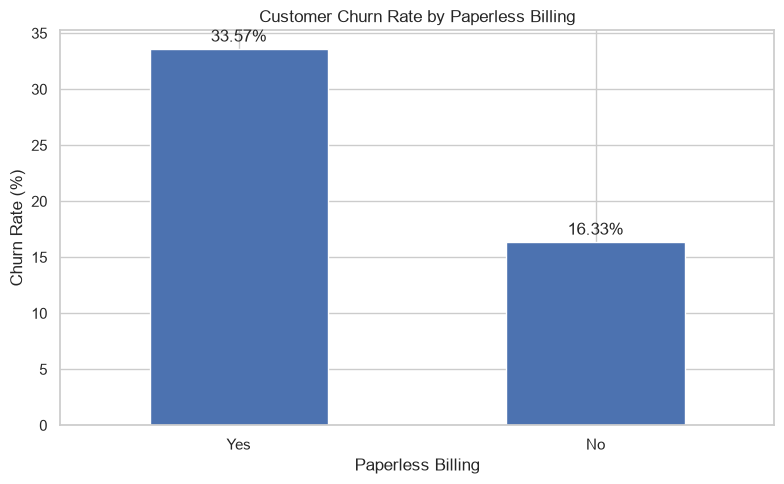

In [20]:

# Visualize churn rate by Paperless Billing

paperless_churn_rate = paperless_churn["Yes"].sort_values(
    ascending=False
)

ax = paperless_churn_rate.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Customer Churn Rate by Paperless Billing")
plt.xlabel("Paperless Billing")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()


In [21]:

# Churn analysis by Senior Citizen status

senior_churn = (
    df.groupby("SeniorCitizen")["Churn"]
    .value_counts(normalize=True)
    .unstack(fill_value=0) * 100
)

# Replace numerical labels with readable names
senior_churn.index = senior_churn.index.map({
    0: "Non-Senior Citizen",
    1: "Senior Citizen"
})

print(senior_churn.round(2))


Churn                  No    Yes
SeniorCitizen                   
Non-Senior Citizen  76.39  23.61
Senior Citizen      58.32  41.68


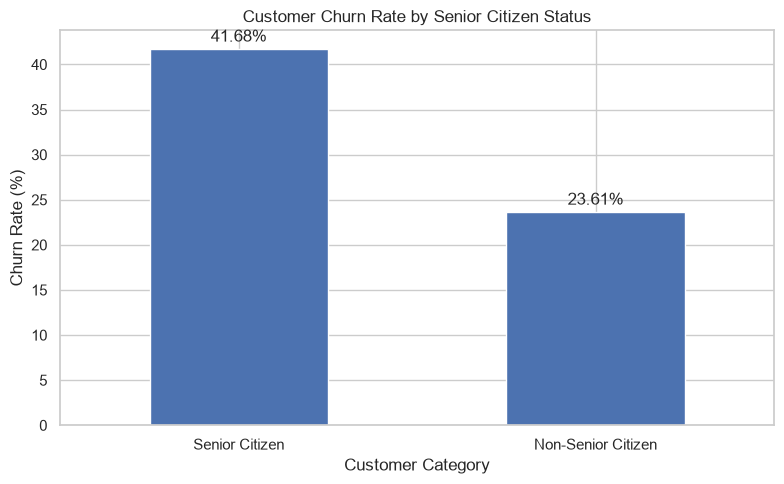

In [22]:

# Visualize churn rate by Senior Citizen status

senior_churn_rate = senior_churn["Yes"].sort_values(
    ascending=False
)

ax = senior_churn_rate.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Customer Churn Rate by Senior Citizen Status")
plt.xlabel("Customer Category")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()


In [23]:

# Revenue exposure by contract type

contract_revenue = (
    df[df["Churn"] == "Yes"]
    .groupby("Contract")["MonthlyCharges"]
    .sum()
    .sort_values(ascending=False)
)

print("Monthly Revenue Exposure by Contract:")
print(contract_revenue.round(2))


Monthly Revenue Exposure by Contract:
Contract
Month-to-month    120847.10
One year           14118.45
Two year            4165.30
Name: MonthlyCharges, dtype: float64


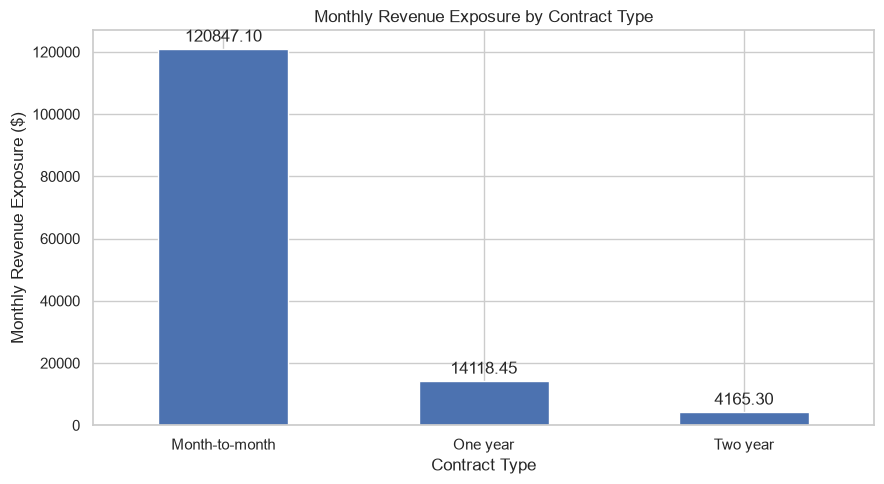

In [24]:

# Visualize revenue exposure by contract

ax = contract_revenue.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Monthly Revenue Exposure by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Monthly Revenue Exposure ($)")
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()


In [25]:

# Monthly revenue exposure by tenure group

tenure_revenue = (
    df[df["Churn"] == "Yes"]
    .groupby("TenureGroup")["MonthlyCharges"]
    .sum()
    .sort_values(ascending=False)
)

print("Monthly Revenue Exposure by Tenure Group:")
print(tenure_revenue.round(2))


Monthly Revenue Exposure by Tenure Group:
TenureGroup
New (0-12 months)           68954.25
Mid-term (25-48 months)     27462.50
Early (13-24 months)        23081.65
Long-term (49-72 months)    19632.45
Name: MonthlyCharges, dtype: float64


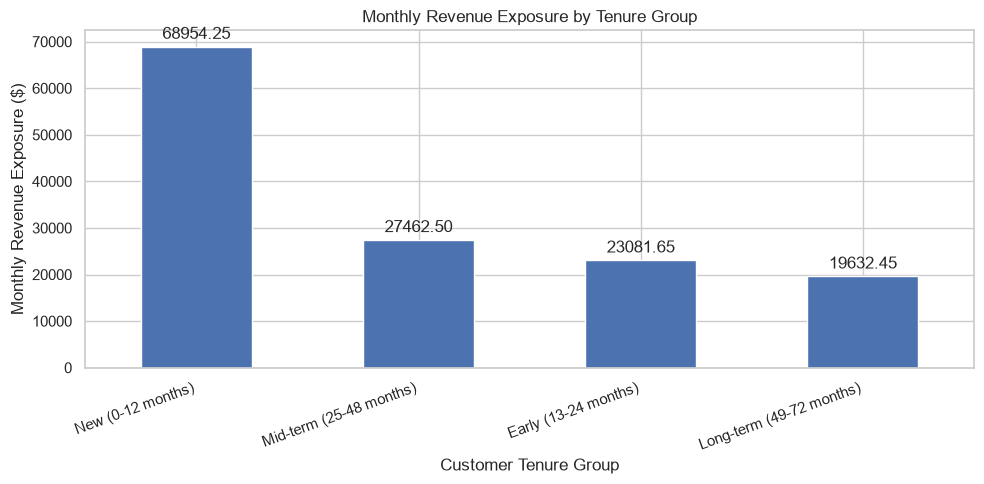

In [26]:

# Visualize revenue exposure by tenure group

ax = tenure_revenue.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Monthly Revenue Exposure by Tenure Group")
plt.xlabel("Customer Tenure Group")
plt.ylabel("Monthly Revenue Exposure ($)")
plt.xticks(rotation=20, ha="right")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()


In [27]:

# Monthly revenue exposure by Internet Service

internet_revenue = (
    df[df["Churn"] == "Yes"]
    .groupby("InternetService")["MonthlyCharges"]
    .sum()
    .sort_values(ascending=False)
)

print("Monthly Revenue Exposure by Internet Service:")
print(internet_revenue.round(2))


Monthly Revenue Exposure by Internet Service:
InternetService
Fiber optic    114300.05
DSL             22529.20
No               2301.60
Name: MonthlyCharges, dtype: float64


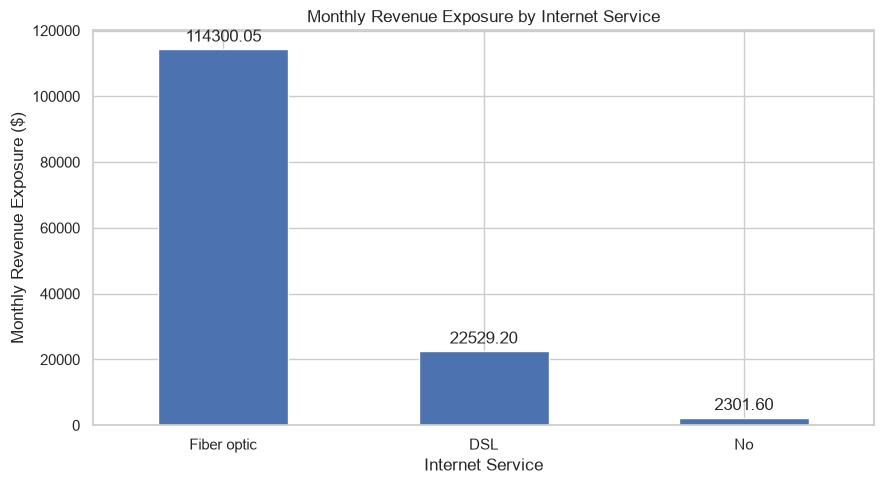

In [28]:

# Visualize revenue exposure by Internet Service

ax = internet_revenue.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Monthly Revenue Exposure by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Monthly Revenue Exposure ($)")
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()


In [29]:

# Monthly revenue exposure by Payment Method

payment_revenue = (
    df[df["Churn"] == "Yes"]
    .groupby("PaymentMethod")["MonthlyCharges"]
    .sum()
    .sort_values(ascending=False)
)

print("Monthly Revenue Exposure by Payment Method:")
print(payment_revenue.round(2))


Monthly Revenue Exposure by Payment Method:
PaymentMethod
Electronic check             84288.75
Bank transfer (automatic)    20091.90
Credit card (automatic)      17946.60
Mailed check                 16803.60
Name: MonthlyCharges, dtype: float64


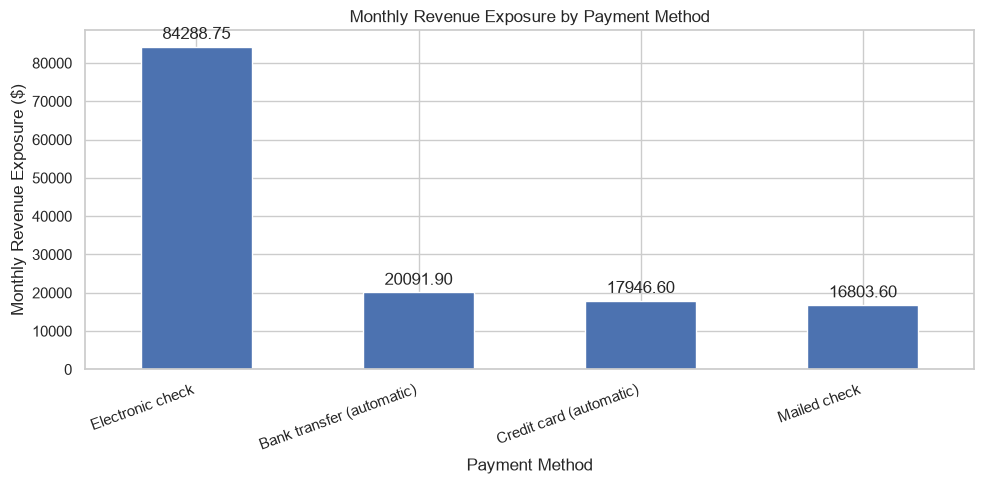

In [30]:

# Visualize revenue exposure by Payment Method

ax = payment_revenue.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Monthly Revenue Exposure by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Monthly Revenue Exposure ($)")
plt.xticks(rotation=20, ha="right")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()


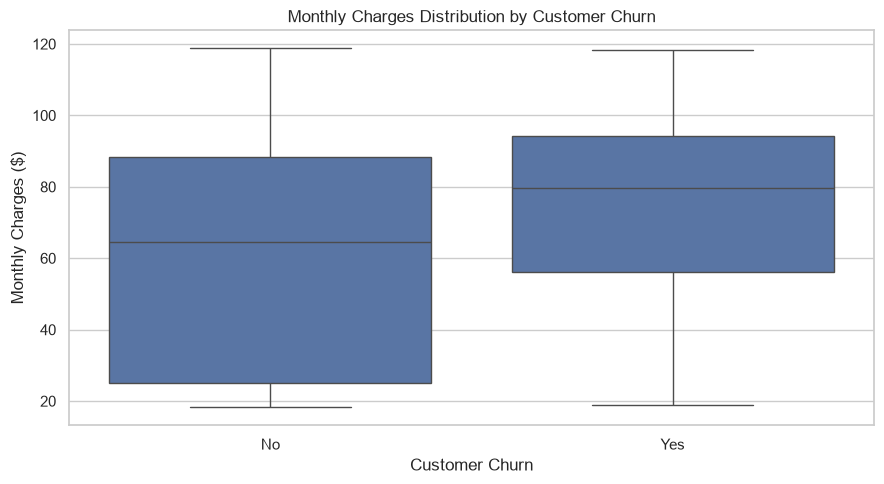

In [31]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges Distribution by Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges ($)")

plt.tight_layout()
plt.show()


In [32]:

monthly_charge_summary = (
    df.groupby("Churn")["MonthlyCharges"]
    .agg(["count", "mean", "median", "std"])
)

print(monthly_charge_summary.round(2))


       count   mean  median    std
Churn                             
No      5174  61.27   64.43  31.09
Yes     1869  74.44   79.65  24.67


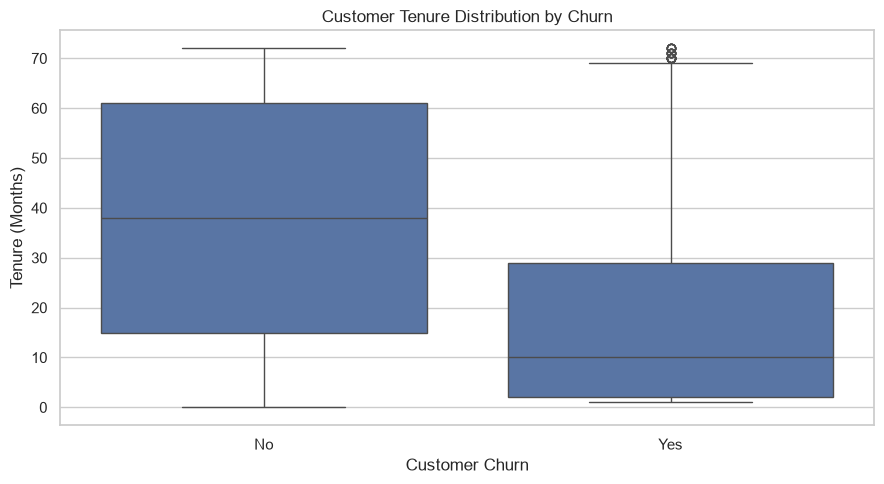

In [33]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Tenure (Months)")

plt.tight_layout()
plt.show()


In [34]:

tenure_summary = (
    df.groupby("Churn")["tenure"]
    .agg(["count", "mean", "median", "std"])
)

print("Tenure Statistics by Customer Churn:")
print(tenure_summary.round(2))


Tenure Statistics by Customer Churn:
       count   mean  median    std
Churn                             
No      5174  37.57    38.0  24.11
Yes     1869  17.98    10.0  19.53


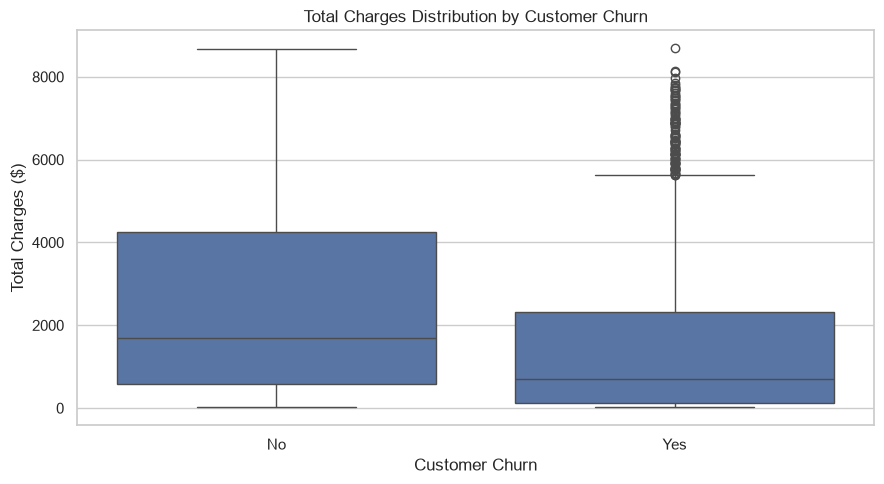

In [35]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="TotalCharges"
)

plt.title("Total Charges Distribution by Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Total Charges ($)")

plt.tight_layout()
plt.show()


In [36]:

total_charges_summary = (
    df.groupby("Churn")["TotalCharges"]
    .agg(["count", "mean", "median", "std"])
)

print("Total Charges Statistics by Customer Churn:")
print(total_charges_summary.round(2))


Total Charges Statistics by Customer Churn:
       count     mean   median      std
Churn                                  
No      5163  2555.34  1683.60  2329.46
Yes     1869  1531.80   703.55  1890.82


In [37]:

from pathlib import Path

# Create visuals folder
visuals_dir = Path("../visuals")
visuals_dir.mkdir(parents=True, exist_ok=True)

print("Visuals folder created:", visuals_dir.resolve())


Visuals folder created: C:\Projects\telecom-customer-churn-analysis\visuals


In [41]:

# ==========================================
# SAVE ALL 15 EDA VISUALIZATIONS
# Telecom Customer Churn Analysis
# ==========================================

from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# Create visuals directory
visuals_dir = Path("../visuals")
visuals_dir.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")


# ------------------------------------------
# 01. Overall Customer Churn Distribution
# ------------------------------------------

plt.figure(figsize=(8, 6))

plt.pie(
    churn_counts,
    labels=churn_counts.index,
    autopct="%1.2f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Overall Customer Churn Distribution")
plt.tight_layout()

plt.savefig(visuals_dir / "01_overall_churn_distribution.png",
            dpi=300, bbox_inches="tight")
plt.close()


# ------------------------------------------
# 02. Churn Rate by Contract Type
# ------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

contract_churn["Yes"].sort_values(ascending=False).plot(
    kind="bar", ax=ax
)

ax.set_title("Customer Churn Rate by Contract Type")
ax.set_xlabel("Contract Type")
ax.set_ylabel("Churn Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(visuals_dir / "02_churn_by_contract.png",
            dpi=300, bbox_inches="tight")
plt.close()


# ------------------------------------------
# 03. Churn Rate by Tenure Group
# ------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

tenure_churn["Yes"].plot(kind="bar", ax=ax)

ax.set_title("Customer Churn Rate by Tenure Group")
ax.set_xlabel("Customer Tenure Group")
ax.set_ylabel("Churn Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(visuals_dir / "03_churn_by_tenure.png",
            dpi=300, bbox_inches="tight")
plt.close()


# ------------------------------------------
# 04. Churn Rate by Payment Method
# ------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

payment_churn["Yes"].sort_values(ascending=False).plot(
    kind="bar", ax=ax
)

ax.set_title("Customer Churn Rate by Payment Method")
ax.set_xlabel("Payment Method")
ax.set_ylabel("Churn Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(visuals_dir / "04_churn_by_payment.png",
            dpi=300, bbox_inches="tight")
plt.close()


# ------------------------------------------
# 05. Churn Rate by Internet Service
# ------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

internet_churn["Yes"].sort_values(ascending=False).plot(
    kind="bar", ax=ax
)

ax.set_title("Customer Churn Rate by Internet Service")
ax.set_xlabel("Internet Service")
ax.set_ylabel("Churn Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(visuals_dir / "05_churn_by_internet.png",
            dpi=300, bbox_inches="tight")
plt.close()


# ------------------------------------------
# 06. Churn Rate by Additional Services
# ------------------------------------------

fig, ax = plt.subplots(figsize=(12, 6))

service_summary_df[
    ["Without Service (%)", "With Service (%)"]
].plot(kind="bar", ax=ax)

ax.set_title("Customer Churn Rate by Additional Services")
ax.set_xlabel("Additional Services")
ax.set_ylabel("Churn Rate (%)")
ax.legend(title="Service Subscription")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(visuals_dir / "06_churn_by_services.png",
            dpi=300, bbox_inches="tight")
plt.close()


# ------------------------------------------
# 07. Churn Rate by Paperless Billing
# ------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

paperless_churn["Yes"].sort_values(ascending=False).plot(
    kind="bar", ax=ax
)

ax.set_title("Customer Churn Rate by Paperless Billing")
ax.set_xlabel("Paperless Billing")
ax.set_ylabel("Churn Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(visuals_dir / "07_churn_by_paperless_billing.png",
            dpi=300, bbox_inches="tight")
plt.close()


# ------------------------------------------
# 08. Churn Rate by Senior Citizen Status
# ------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

senior_churn["Yes"].sort_values(ascending=False).plot(
    kind="bar", ax=ax
)

ax.set_title("Customer Churn Rate by Senior Citizen Status")
ax.set_xlabel("Customer Category")
ax.set_ylabel("Churn Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(visuals_dir / "08_churn_by_senior_citizen.png",
            dpi=300, bbox_inches="tight")
plt.close()


# ------------------------------------------
# 09. Revenue Exposure by Contract
# ------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

contract_revenue.plot(kind="bar", ax=ax)

ax.set_title("Monthly Revenue Exposure by Contract Type")
ax.set_xlabel("Contract Type")
ax.set_ylabel("Monthly Revenue Exposure ($)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(visuals_dir / "09_revenue_by_contract.png",
            dpi=300, bbox_inches="tight")
plt.close()


# ------------------------------------------
# 10. Revenue Exposure by Tenure
# ------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

tenure_revenue.plot(kind="bar", ax=ax)

ax.set_title("Monthly Revenue Exposure by Tenure Group")
ax.set_xlabel("Customer Tenure Group")
ax.set_ylabel("Monthly Revenue Exposure ($)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(visuals_dir / "10_revenue_by_tenure.png",
            dpi=300, bbox_inches="tight")
plt.close()


# ------------------------------------------
# 11. Revenue Exposure by Internet Service
# ------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

internet_revenue.plot(kind="bar", ax=ax)

ax.set_title("Monthly Revenue Exposure by Internet Service")
ax.set_xlabel("Internet Service")
ax.set_ylabel("Monthly Revenue Exposure ($)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(visuals_dir / "11_revenue_by_internet.png",
            dpi=300, bbox_inches="tight")
plt.close()


# ------------------------------------------
# 12. Revenue Exposure by Payment Method
# ------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

payment_revenue.plot(kind="bar", ax=ax)

ax.set_title("Monthly Revenue Exposure by Payment Method")
ax.set_xlabel("Payment Method")
ax.set_ylabel("Monthly Revenue Exposure ($)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(visuals_dir / "12_revenue_by_payment.png",
            dpi=300, bbox_inches="tight")
plt.close()


# ------------------------------------------
# 13. Monthly Charges Distribution by Churn
# ------------------------------------------

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges Distribution by Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges ($)")
plt.tight_layout()

plt.savefig(visuals_dir / "13_monthly_charges_boxplot.png",
            dpi=300, bbox_inches="tight")
plt.close()


# ------------------------------------------
# 14. Tenure Distribution by Churn
# ------------------------------------------

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Tenure (Months)")
plt.tight_layout()

plt.savefig(visuals_dir / "14_tenure_boxplot.png",
            dpi=300, bbox_inches="tight")
plt.close()


# ------------------------------------------
# 15. Total Charges Distribution by Churn
# ------------------------------------------

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="TotalCharges"
)

plt.title("Total Charges Distribution by Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Total Charges ($)")
plt.tight_layout()

plt.savefig(visuals_dir / "15_total_charges_boxplot.png",
            dpi=300, bbox_inches="tight")
plt.close()


# ------------------------------------------
# FINAL VALIDATION
# ------------------------------------------

saved_files = list(visuals_dir.glob("*.png"))

print("EDA Visualization Export Completed!")
print("------------------------------------")
print("Total PNG files saved:", len(saved_files))

for file in sorted(saved_files):
    print(file.name)


EDA Visualization Export Completed!
------------------------------------
Total PNG files saved: 15
01_overall_churn_distribution.png
02_churn_by_contract.png
03_churn_by_tenure.png
04_churn_by_payment.png
05_churn_by_internet.png
06_churn_by_services.png
07_churn_by_paperless_billing.png
08_churn_by_senior_citizen.png
09_revenue_by_contract.png
10_revenue_by_tenure.png
11_revenue_by_internet.png
12_revenue_by_payment.png
13_monthly_charges_boxplot.png
14_tenure_boxplot.png
15_total_charges_boxplot.png


In [40]:

from pathlib import Path

# Get the notebook's current working directory
print("Current directory:", Path.cwd())

# Correct path to visuals folder
visuals_dir = Path.cwd().parent / "visuals"

# Create folder if it does not exist
visuals_dir.mkdir(parents=True, exist_ok=True)

print("Visuals folder:", visuals_dir.resolve())
print("Folder exists:", visuals_dir.exists())


Current directory: c:\Projects\telecom-customer-churn-analysis\notebooks
Visuals folder: C:\Projects\telecom-customer-churn-analysis\visuals
Folder exists: True
